<a href="https://colab.research.google.com/github/govindanama1430-sketch/RAG/blob/main/data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Notebook 2: Data Preparation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `sampled_data.csv` — Created by Notebook 1
- [ ] `corporate_policies/` folder with `.md` SOP files
- [ ] Internet access (to download the tokenizer)

**Files this notebook will CREATE:**
- [ ] `./tokenized_train/`, `./tokenized_valid/`, `./tokenized_test/` — HuggingFace datasets _(Required by NB6)_
- [ ] `df_test.csv` — Test set with readable text + labels _(Required by NB5 and NB7)_

---

### Setup
Installs dependencies, defines helpers and (for Notebooks 3-7) loads the shared `config.json` written by Notebook 2. Run this cell first.

In [ ]:
# ---- Environment setup (Google Colab / local Jupyter) ----
import os, sys, glob, zipfile, json, random, warnings
warnings.filterwarnings("ignore")

USE_DRIVE = False   # set True on Colab to keep artifacts (chroma_db, adapters, csv) across runtime resets
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/GenAI_Capstone"
    os.makedirs(WORKDIR, exist_ok=True)
    os.chdir(WORKDIR)
print("Working directory:", os.getcwd())

%pip install -q datasets transformers pandas numpy scikit-learn matplotlib seaborn langchain-community langchain-text-splitters

def find_sop_dir():
    """Locate the folder holding the Markdown SOP files (corporate_policies/ or Dataset/sop_documents/).
    If it is not present, try to unzip a Dataset*.zip, and finally ask for an upload on Colab."""
    def _search():
        for c in ["corporate_policies", os.path.join("Dataset", "sop_documents"), "sop_documents"]:
            if os.path.isdir(c) and glob.glob(os.path.join(c, "*.md")):
                return c
        for pat in ["**/sop_documents", "**/corporate_policies"]:
            for h in glob.glob(pat, recursive=True):
                if glob.glob(os.path.join(h, "*.md")):
                    return h
        return None
    found = _search()
    if found: return found
    for z in glob.glob("*.zip") + glob.glob("**/Dataset*.zip", recursive=True):
        with zipfile.ZipFile(z) as zf: zf.extractall(".")
        found = _search()
        if found: return found
    try:
        from google.colab import files
        print("SOP folder not found - please upload Dataset.zip (contains sop_documents/*.md)")
        for name in files.upload():
            if name.endswith(".zip"):
                with zipfile.ZipFile(name) as zf: zf.extractall(".")
        found = _search()
        if found: return found
    except ImportError:
        pass
    raise FileNotFoundError("Could not find the SOP .md files. Place them in ./corporate_policies/ or ./Dataset/sop_documents/")

Working directory: /content
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


## **Stage 2: Data Preparation**
### **Task 2.1: Clean and Validate Dataset**

#### **2.1.1 Remove Duplicate and Invalid Records [2 marks]**
**The Task:** Identify and remove duplicate records using normalised deduplication (lowercase + strip before comparison), plus any invalid, incomplete, or corrupted records.

**Hints & Tips:**
* Load `sampled_data.csv` from Notebook 1 first.
* Normalised dedup: create a temporary `_norm` column = `instruction.str.lower().str.strip()`, drop duplicates on it, then drop the helper column.
* Check for nulls in `instruction`, `intent`, and `category` — drop rows missing any of these targets.
* Print the number of rows removed so the cleaning is auditable.

**Why we are doing it:** To prevent degraded training from redundant or broken records, and to stop near-duplicates leaking across train/test splits later.
**How we are doing it:** Pandas normalised deduplication and null filtering.

**Learner Inference:** Exact-match dedup misses `"Where is my order?"` vs `"where is my order?"`. Normalising first catches these and keeps your splits clean.

In [ ]:
import re, json, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)

df = pd.read_csv("/content/drive/MyDrive/RAG/sampled_data.csv")
print("Loaded sampled_data.csv:", df.shape)
KEY_COLS = ["instruction", "intent", "category"]
n0 = len(df)

# invalid / incomplete / corrupted records ---------------------------------------------------------
n_null = int(df[KEY_COLS].isnull().any(axis=1).sum())
df = df.dropna(subset=KEY_COLS)
blank = df[KEY_COLS].astype(str).apply(lambda s: s.str.strip() == "").any(axis=1)
corrupt = df["instruction"].astype(str).str.contains("�", regex=False) | (df["instruction"].astype(str).str.split().str.len() < 2)
n_blank, n_corrupt = int(blank.sum()), int((corrupt & ~blank).sum())
df = df[~(blank | corrupt)]

# NORMALISED de-duplication: lower-case + strip BEFORE comparing ------------------------------------
df["_norm"] = df["instruction"].astype(str).str.lower().str.strip()
n_dup = int(df.duplicated(subset="_norm").sum())
df = df.drop_duplicates(subset="_norm").drop(columns="_norm").reset_index(drop=True)

print(f"Rows at start: {n0}")
print(f"  removed - null key fields     : {n_null}")
print(f"  removed - empty/blank strings : {n_blank}")
print(f"  removed - corrupted/too short : {n_corrupt}")
print(f"  removed - normalised duplicates: {n_dup}")
print(f"Rows remaining: {len(df)}  (total removed: {n0 - len(df)})")
assert 1000 <= len(df) <= 5000, "dataset must have 1,000-5,000 valid records"

Loaded sampled_data.csv: (4000, 3)
Rows at start: 4000
  removed - null key fields     : 0
  removed - empty/blank strings : 0
  removed - corrupted/too short : 1
  removed - normalised duplicates: 0
Rows remaining: 3999  (total removed: 1)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# New section

#### **2.1.2 Standardise Dataset Formatting [2 marks]**
**The Task:** Clean the strings inside `instruction`, `intent`, and `category` by stripping whitespace and enforcing uniform casing (intents = lower, categories = upper).

**Hints & Tips:**
* Use Pandas `.str.strip()`, `.str.lower()`, `.str.upper()`.
* Always strip whitespace BEFORE lowering — trailing spaces survive `.lower()`.
* Standardised casing prevents the model treating "Refund" and "refund" as different classes.

**Why we are doing it:** To ensure raw strings are perfectly standardised before injecting them into prompt templates.
**How we are doing it:** Pandas string manipulation.

**Learner Inference:** Standardising capitalisation prevents the model from treating the same intent written two ways as two separate classes.

In [ ]:
# strip FIRST, then change case (trailing spaces survive .lower())
df["instruction"] = df["instruction"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
df["intent"]      = df["intent"].astype(str).str.strip().str.lower()
df["category"]    = df["category"].astype(str).str.strip().str.upper()

# collapsing inner whitespace can create new duplicates -> re-check
norm = df["instruction"].str.lower().str.strip()
extra = int(norm.duplicated().sum())
if extra:
    df = df[~norm.duplicated()].reset_index(drop=True)
    print(f"Removed {extra} duplicates exposed by whitespace standardisation")

# schema validation
assert list(df.columns) == ["instruction", "intent", "category"]
assert df["intent"].str.fullmatch(r"[a-z]+(_[a-z]+)*").all(), "intents must be lower snake_case"
assert (df["category"] == df["category"].str.upper()).all()
assert (df.groupby("intent")["category"].nunique() == 1).all()
print("Standardised dataset:", df.shape)
print("Intents:", df["intent"].nunique(), "| Categories:", sorted(df["category"].unique()))
display(df.head())

Removed 3 duplicates exposed by whitespace standardisation
Standardised dataset: (3996, 3)
Intents: 27 | Categories: ['ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICE', 'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION']


,instruction,intent,category
0,i have lost my account access key where can i ...,recover_password,ACCOUNT
1,I need help leaving my fucking feedback about ...,review,FEEDBACK
2,wanna see ur payment modalities will yahelp me,check_payment_methods,PAYMENT
3,there are issues trying to update the goddamn ...,change_shipping_address,SHIPPING
4,"I cannot remember my damn profile key, how to ...",recover_password,ACCOUNT


### **Task 2.2: Create Instruction-Tuning Dataset**

#### **2.2.1 Transform Records into Instruction Format [2 marks]**
**The Task:** Wrap the raw instructions and targets into a standardized `ChatML` format, forcing the assistant's response to be a strict JSON string containing the `intent` and `category`.

**Hints & Tips:**
* Use the Qwen tokenizer's `apply_chat_template(tokenize=False)`.
* The target JSON is `{"intent": "...", "category": "..."}` — built via `json.dumps()`.

**Model Selection:**
* **Qwen/Qwen2.5-1.5B-Instruct** (recommended) — fits T4, strong instruction following.
* **TinyLlama-1.1B-Chat** — lighter but weaker at structured output.
* **Llama-3-8B-Instruct** — best quality, needs >16GB VRAM even in 4-bit.
* Whatever you pick, set `MODEL_ID` here and in ALL later notebooks.

**Learner Inference:** Formatting the target as JSON establishes the exact structural rules the LoRA model learns to mimic in Stage 4.

In [ ]:
from transformers import AutoTokenizer

# ===== Project-wide configuration (written to config.json at the end of this notebook) ============
MODEL_ID    = "Qwen/Qwen2.5-1.5B-Instruct"                    # SAME in every notebook
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"          # SAME in every notebook
ROUTER_SYSTEM = ("You are an intent classification router for a customer support system. "
                 "Read the customer message and reply with ONLY a JSON object of the form "
                 '{"intent": "<intent>", "category": "<CATEGORY>"} and nothing else.')
BASELINE_SYSTEM = "You are a helpful customer support assistant. Keep the answer concise."
RAG_SYSTEM = ("You are a customer support assistant. Answer strictly using this SOP:\n{context}\n"
              "If the SOP does not cover the question, say that you will escalate to a human agent. Keep the answer concise.")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = "right"        # training uses right padding (generation notebooks switch to left)
print("pad_token:", tokenizer.pad_token, tokenizer.pad_token_id, "| eos_token:", tokenizer.eos_token, tokenizer.eos_token_id)

def build_messages(row, with_answer=True):
    msgs = [{"role": "system", "content": ROUTER_SYSTEM},
            {"role": "user", "content": row["instruction"]}]
    if with_answer:
        target = json.dumps({"intent": row["intent"], "category": row["category"]})
        msgs.append({"role": "assistant", "content": target})
    return msgs

df["text"]        = [tokenizer.apply_chat_template(build_messages(r), tokenize=False) for _, r in df.iterrows()]
df["prompt_text"] = [tokenizer.apply_chat_template(build_messages(r, False), tokenize=False, add_generation_prompt=True) for _, r in df.iterrows()]
assert all(t.startswith(p) for t, p in zip(df["text"], df["prompt_text"])), "full text must start with the prompt part"
print("Example ChatML training string:\n" + "-" * 60 + "\n" + df["text"].iloc[0] + "\n" + "-" * 60)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

pad_token: <|endoftext|> 151643 | eos_token: <|im_end|> 151645
Example ChatML training string:
------------------------------------------------------------
<|im_start|>system
You are an intent classification router for a customer support system. Read the customer message and reply with ONLY a JSON object of the form {"intent": "<intent>", "category": "<CATEGORY>"} and nothing else.<|im_end|>
<|im_start|>user
i have lost my account access key where can i recover it<|im_end|>
<|im_start|>assistant
{"intent": "recover_password", "category": "ACCOUNT"}<|im_end|>

------------------------------------------------------------


#### **2.2.2 Validate Instruction Templates [2 marks]**
**The Task:** Extract the assistant's portion of the generated ChatML string and parse it with `json.loads()` to verify structural integrity.

**Hints & Tips:**
* Split the string by `<|im_start|>assistant` and parse what follows.
* If this throws `JSONDecodeError`, your formatting in 2.2.1 is broken — fix before training.
* Validate several samples, not just the first.

**Learner Inference:** A JSONDecodeError here means the model would learn broken syntax. Catching it now saves a failed training run.

In [ ]:
def extract_assistant_json(chatml):
    tail = chatml.split("<|im_start|>assistant")[-1]
    tail = tail.split("<|im_end|>")[0].strip()
    return json.loads(tail)              # raises JSONDecodeError if the target is malformed

bad = []
for i, (txt, intent, cat) in enumerate(zip(df["text"], df["intent"], df["category"])):
    try:
        obj = extract_assistant_json(txt)
        assert set(obj) == {"intent", "category"}, "schema keys"
        assert obj["intent"] == intent and obj["category"] == cat, "value mismatch"
    except Exception as e:
        bad.append((i, repr(e)))
print(f"Validated ALL {len(df)} ChatML records -> failures: {len(bad)}")
assert not bad, bad[:5]
print("Sample parsed targets:", [extract_assistant_json(t) for t in df['text'].iloc[:3]])
print("Template consistency: every record has exactly one system, one user and one assistant turn:",
      all(t.count("<|im_start|>system") == 1 and t.count("<|im_start|>user") == 1 and t.count("<|im_start|>assistant") == 1 for t in df["text"]))

Validated ALL 3996 ChatML records -> failures: 0
Sample parsed targets: [{'intent': 'recover_password', 'category': 'ACCOUNT'}, {'intent': 'review', 'category': 'FEEDBACK'}, {'intent': 'check_payment_methods', 'category': 'PAYMENT'}]
Template consistency: every record has exactly one system, one user and one assistant turn: True


### **Task 2.3: Engineer Training and Retrieval Data**

#### **2.3.1 Tokenise Dataset [2 marks]**
**The Task:** Convert text sequences into tensor IDs and apply `-100` masking to padding tokens in the `labels` array.

**Hints & Tips:**
* If a token equals `tokenizer.pad_token_id`, replace it with `-100` in labels.
* `-100` is PyTorch's ignore index — the loss skips these tokens.

**Parameter Tuning:**
* `max_length`: `128` (fast, fits most Bitext prompts), `256` (safer if truncation seen), `64` (too aggressive).

**Learner Inference:** Masking isolates the loss — the model is penalised for wrong JSON, not for padding.

In [ ]:
from datasets import Dataset

# choose the smallest max_length with <1% truncation (candidates from the assignment: 128 / 192 / 256)
full_lens = np.array([len(x) for x in tokenizer(df["text"].tolist(), add_special_tokens=False)["input_ids"]])
for cand in (128, 192, 256):
    trunc_rate = (full_lens > cand).mean() * 100
    print(f"max_length={cand}: {trunc_rate:.2f}% of rows would be truncated")
    if trunc_rate < 1.0:
        MAX_LENGTH = cand; break
else:
    MAX_LENGTH = 256
print("Selected MAX_LENGTH =", MAX_LENGTH)

enc = tokenizer(df["text"].tolist(), max_length=MAX_LENGTH, truncation=True, padding="max_length")
prompt_lens = np.array([len(x) for x in tokenizer(df["prompt_text"].tolist(), add_special_tokens=False)["input_ids"]])

labels = []
for ids, plen in zip(enc["input_ids"], prompt_lens):
    lab = [(-100 if t == tokenizer.pad_token_id else t) for t in ids]   # padding -> -100 (ignored by the loss)
    lab[:plen] = [-100] * min(plen, len(lab))                            # system+user tokens -> -100: loss only on the JSON answer
    labels.append(lab)

tok_all = Dataset.from_dict({"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"], "labels": labels})
print(tok_all)

# sanity: the supervised tokens decode to exactly "<JSON><|im_end|>"
ex = tok_all[0]
sup = [t for t, l in zip(ex["input_ids"], ex["labels"]) if l != -100]
print("Supervised tokens decode to:", repr(tokenizer.decode(sup)))
n_sup = np.array([sum(l != -100 for l in lab) for lab in labels])
assert (n_sup > 0).all(), "some rows have no supervised tokens (JSON truncated away)"
print(f"Supervised tokens per row: mean {n_sup.mean():.1f}, min {n_sup.min()}, max {n_sup.max()}")

max_length=128: 0.00% of rows would be truncated
Selected MAX_LENGTH = 128
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 3996
})
Supervised tokens decode to: '{"intent": "recover_password", "category": "ACCOUNT"}<|im_end|>\n'
Supervised tokens per row: mean 16.1, min 15, max 18


#### **2.3.2 Analyse Token Distributions [2 marks]**
**The Task:** Analyse the token-count distribution to detect truncation risks and verify the sequence-length configuration.

**Hints & Tips:**
* Count non-padding tokens per row and plot a histogram.
* If >5% of rows hit `max_length`, increase it.
* The JSON target is ~20 tokens — if truncated, the model learns incomplete output.

**Learner Inference:** Sequences hitting the ceiling mean the JSON target is getting cut off, teaching the model to produce broken output.

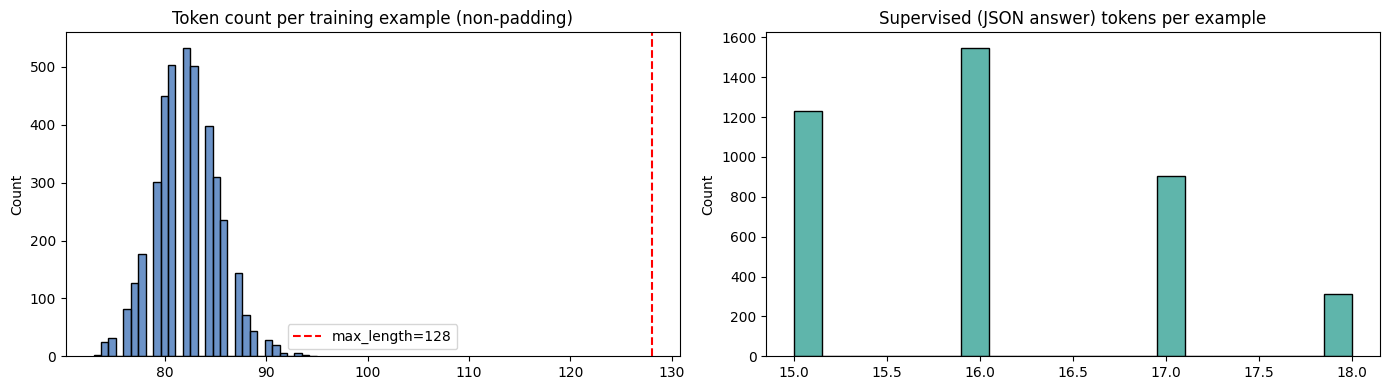

Token count: mean 82.2 | median 82 | p95 87 | max 95
Rows hitting the max_length ceiling: 0.00%  (threshold 5%)
Answer (JSON) length: ~16 tokens (includes <|im_end|>) -> well inside the window
Truncation risk: LOW - JSON targets are not being cut off.


In [ ]:
non_pad = np.array([sum(m) for m in tok_all["attention_mask"]])
at_ceiling = (non_pad >= MAX_LENGTH).mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(non_pad, bins=30, ax=ax[0], color="#3b6fb6"); ax[0].axvline(MAX_LENGTH, color="red", ls="--", label=f"max_length={MAX_LENGTH}")
ax[0].set_title("Token count per training example (non-padding)"); ax[0].legend()
sns.histplot(n_sup, bins=20, ax=ax[1], color="#2a9d8f"); ax[1].set_title("Supervised (JSON answer) tokens per example")
plt.tight_layout(); plt.show()

print(f"Token count: mean {non_pad.mean():.1f} | median {np.median(non_pad):.0f} | p95 {np.percentile(non_pad,95):.0f} | max {non_pad.max()}")
print(f"Rows hitting the max_length ceiling: {at_ceiling:.2f}%  (threshold 5%)")
print(f"Answer (JSON) length: ~{n_sup.mean():.0f} tokens (includes <|im_end|>) -> well inside the window")
assert at_ceiling < 5, "increase MAX_LENGTH - too many truncated rows"
print("Truncation risk: LOW - JSON targets are not being cut off." if at_ceiling < 1 else "Truncation risk: MODERATE - monitor.")

#### **2.3.3 Prepare Retrieval Corpus [3 marks]**
**The Task:** Ingest the Markdown SOPs into LangChain Document objects ready to be embedded.

**Hints & Tips:**
* Use `TextLoader` from LangChain.
* Each `.md` file becomes one `Document` with `.page_content` and `.metadata`.
* These documents are embedded into ChromaDB in Notebook 4.

**Learner Inference:** These document objects form the knowledge base your bot retrieves from in Stages 3 and 4.

In [ ]:
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

SOP_DIR = find_sop_dir()
sop_docs = []
for f in sorted(glob.glob(os.path.join(SOP_DIR, "*.md"))):
    d = TextLoader(f, encoding="utf-8").load()[0]
    d.metadata["doc_name"] = os.path.basename(f)
    d.metadata["title"] = d.page_content.splitlines()[0].lstrip("# ").strip()
    sop_docs.append(d)

# --- corpus quality validation
assert all(d.page_content.strip() for d in sop_docs), "empty SOP document"
assert len({d.metadata["doc_name"] for d in sop_docs}) == len(sop_docs)
wc = [len(d.page_content.split()) for d in sop_docs]
print(f"{len(sop_docs)} SOP documents loaded | words per doc: min {min(wc)}, mean {np.mean(wc):.0f}, max {max(wc)}")
display(pd.DataFrame([{"doc": d.metadata["doc_name"], "title": d.metadata["title"], "words": len(d.page_content.split()),
                       "est_tokens": len(tokenizer(d.page_content)["input_ids"])} for d in sop_docs]))

# --- chunking analysis (LangChain splitter). SOPs are ~250 words, so each file is kept as ONE retrieval unit;
#     chunking is evaluated to justify that decision (a clause-level chunk would lose the SOP title that the router queries on).
splitter = RecursiveCharacterTextSplitter(chunk_size=800, chunk_overlap=100)
chunks = splitter.split_documents(sop_docs)
print(f"\nChunking analysis (800 chars / 100 overlap): {len(chunks)} chunks from {len(sop_docs)} docs "
      f"({len(chunks)/len(sop_docs):.1f} chunks per doc)")
print("Decision: index WHOLE documents (1 doc = 1 vector) - SOPs are short and self-contained; "
      "this keeps the Chroma count equal to the number of SOP files (validated in Notebook 4).")
print("Note: all-MiniLM-L6-v2 embeds at most 256 word-pieces; the full SOP text is still passed to the LLM as context.")

# --- Intent -> SOP mapping (design assumption, documented in the proposal) --------------------------
INTENT_TO_SOP = {
    "cancel_order": "order_tracking.md", "change_order": "order_tracking.md",
    "change_shipping_address": "order_tracking.md", "set_up_shipping_address": "order_tracking.md",
    "track_order": "order_tracking.md",
    "delivery_options": "shipping_delays.md", "delivery_period": "shipping_delays.md",
    "check_cancellation_fee": "subscription_cancellation.md",
    "check_invoice": "billing_disputes.md", "get_invoice": "billing_disputes.md",
    "check_payment_methods": "payment_methods.md", "payment_issue": "payment_methods.md", "place_order": "payment_methods.md",
    "check_refund_policy": "refund_policy.md", "get_refund": "refund_policy.md", "track_refund": "refund_policy.md",
    "complaint": "escalation_matrix.md", "contact_human_agent": "escalation_matrix.md", "review": "escalation_matrix.md",
    "contact_customer_service": "working_hours.md",
    "create_account": "account_recovery.md", "switch_account": "account_recovery.md",
    "delete_account": "data_privacy.md", "edit_account": "data_privacy.md", "newsletter_subscription": "data_privacy.md",
    "recover_password": "password_reset.md",
    "registration_problems": "technical_troubleshooting.md",
}
doc_titles = {d.metadata["doc_name"]: d.metadata["title"] for d in sop_docs}
unmapped = sorted(set(df["intent"]) - set(INTENT_TO_SOP))
bad_files = sorted({v for v in INTENT_TO_SOP.values() if v not in doc_titles})
assert not unmapped, f"intents without an SOP mapping: {unmapped}"
assert not bad_files, f"mapping points to missing SOP files: {bad_files}"
# vector-search string used by the Hybrid router: "<SOP title>: <intent in words>"  (e.g. "Shipping Delays: delivery period")
INTENT_SEARCH = {i: f"{doc_titles[f]}: {i.replace('_', ' ')}" for i, f in INTENT_TO_SOP.items()}
print(f"\nIntent->SOP mapping covers all {df['intent'].nunique()} dataset intents ({len(INTENT_TO_SOP)} mapped, {len(set(INTENT_TO_SOP.values()))} distinct SOPs).")
print("Example search strings:", list(INTENT_SEARCH.items())[:3])

13 SOP documents loaded | words per doc: min 228, mean 247, max 280


,doc,title,words,est_tokens
0,account_recovery.md,Account Recovery,240,310
1,billing_disputes.md,Billing Disputes,250,342
2,data_privacy.md,Data Privacy,254,334
3,escalation_matrix.md,Escalation Matrix,234,324
4,order_tracking.md,Order Tracking,245,324
5,password_reset.md,Password Reset,258,336
6,payment_methods.md,Payment Methods,255,333
7,product_return.md,Product Return,243,327
8,refund_policy.md,Refund Policy,280,366
9,shipping_delays.md,Shipping Delays,247,330



Chunking analysis (800 chars / 100 overlap): 38 chunks from 13 docs (2.9 chunks per doc)
Decision: index WHOLE documents (1 doc = 1 vector) - SOPs are short and self-contained; this keeps the Chroma count equal to the number of SOP files (validated in Notebook 4).
Note: all-MiniLM-L6-v2 embeds at most 256 word-pieces; the full SOP text is still passed to the LLM as context.

Intent->SOP mapping covers all 27 dataset intents (27 mapped, 12 distinct SOPs).
Example search strings: [('cancel_order', 'Order Tracking: cancel order'), ('change_order', 'Order Tracking: change order'), ('change_shipping_address', 'Order Tracking: change shipping address')]


### **Task 2.4: Create Dataset Partitions**

#### **2.4.1 Create Train, Validation, and Test Splits [5 marks]**
**The Task:** Split the tokenized dataset into Train (80%), Validation (10%), and Test (10%) partitions using stratified sampling. Demonstrate zero data leakage across all three.

**Hints & Tips:**
* Use `train_test_split` from sklearn with `stratify=df['intent']` so every intent appears in all splits.
* Split twice: first 80/20, then split the 20% into 50/50 (giving 10%/10%).
* The validation set is not optional — it is actively used during fine-tuning (Stage 4 / Notebook 6) for loss monitoring and early stopping.
* The test set must stay completely independent — used only for final evaluation.
* Verify zero overlap with set-intersection checks: `assert len(train_set & test_set) == 0`.
* Build a `df_test` DataFrame preserving readable `text`/`intent`/`category` columns for later scoring.

**Parameter Tuning:**
* Split ratio: `80/10/10` (recommended) or `70/15/15`. Any alternative must be justified.

**Why we are doing it:** To guarantee isolated, unseen data for unbiased evaluation, and a validation set for overfitting detection.
**How we are doing it:** Stratified sklearn splits with explicit programmatic leakage verification.

**Learner Inference:** Testing on data the model trained on gives false confidence (leakage). The held-out test split proves your model handles completely new phrasing; the validation split tells you when to stop training.

In [ ]:
from sklearn.model_selection import train_test_split

df = df.reset_index(drop=True)          # row order == tok_all order (needed to slice the tokenised dataset)
df["row_id"] = df.index
# 80 / 10 / 10 stratified by intent: split 80/20, then split the 20% into 50/50
train_idx, temp_idx = train_test_split(df.index, test_size=0.20, stratify=df["intent"], random_state=SEED)
valid_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=df.loc[temp_idx, "intent"], random_state=SEED)
df_train, df_valid, df_test_full = df.loc[train_idx], df.loc[valid_idx], df.loc[test_idx]
print(f"Train {len(df_train)} ({len(df_train)/len(df):.0%}) | Valid {len(df_valid)} ({len(df_valid)/len(df):.0%}) | Test {len(df_test_full)} ({len(df_test_full)/len(df):.0%})")

# every intent present in every split
all_intents = set(df["intent"])
for name, part in [("train", df_train), ("valid", df_valid), ("test", df_test_full)]:
    assert set(part["intent"]) == all_intents, f"{name} split is missing intents"
print(f"All {len(all_intents)} intents appear in all three splits.")
dist = pd.DataFrame({"train %": df_train["intent"].value_counts(normalize=True), "valid %": df_valid["intent"].value_counts(normalize=True),
                     "test %": df_test_full["intent"].value_counts(normalize=True)}).mul(100).round(2)
display(dist.head(8))

# ---- programmatic LEAKAGE audit (normalised text + row ids) -------------------------------------
norm = lambda s: set(s["instruction"].str.lower().str.strip())
tr, va, te = norm(df_train), norm(df_valid), norm(df_test_full)
assert len(tr & va) == 0 and len(tr & te) == 0 and len(va & te) == 0, "duplicate prompts across partitions!"
assert not (set(df_train.row_id) & set(df_valid.row_id)) and not (set(df_train.row_id) & set(df_test_full.row_id)) and not (set(df_valid.row_id) & set(df_test_full.row_id))
assert len(df_train) + len(df_valid) + len(df_test_full) == len(df)
print(f"Leakage audit PASSED: |train&valid|={len(tr & va)}, |train&test|={len(tr & te)}, |valid&test|={len(va & te)} (normalised prompts)")

# tokenised partitions + readable test frame
tok_train, tok_valid, tok_test = (tok_all.select(list(p.index)) for p in (df_train, df_valid, df_test_full))
to_readable = lambda d: d[["row_id", "instruction", "intent", "category"]].rename(columns={"instruction": "text"}).reset_index(drop=True)
df_test = to_readable(df_test_full)
print("Tokenised sizes:", len(tok_train), len(tok_valid), len(tok_test), "| df_test columns:", list(df_test.columns))

Train 3196 (80%) | Valid 400 (10%) | Test 400 (10%)
All 27 intents appear in all three splits.


,train %,valid %,test %
intent,,,
cancel_order,1.88,2.00,1.75
change_order,3.32,3.25,3.25
change_shipping_address,4.04,4.25,4.00
check_cancellation_fee,3.97,4.00,4.00
check_invoice,4.41,4.50,4.50
check_payment_methods,4.13,4.00,4.25
check_refund_policy,3.79,3.75,3.75
complaint,3.97,4.00,4.00


Leakage audit PASSED: |train&valid|=0, |train&test|=0, |valid&test|=0 (normalised prompts)
Tokenised sizes: 3196 400 400 | df_test columns: ['row_id', 'text', 'intent', 'category']


---
## Save Artifacts for Downstream Notebooks

**IMPORTANT:** These cells save all datasets. Notebooks 5, 6, and 7 depend on them.

In [ ]:
import shutil
for name, ds in [("tokenized_train", tok_train), ("tokenized_valid", tok_valid), ("tokenized_test", tok_test)]:
    shutil.rmtree(f"./{name}", ignore_errors=True)
    ds.save_to_disk(f"./{name}")
df_test.to_csv("df_test.csv", index=False)
to_readable(df_train).to_csv("df_train.csv", index=False)
to_readable(df_valid).to_csv("df_valid.csv", index=False)

# Single source of truth for every later notebook (same MODEL_ID, embedding model, prompts, mappings)
config = {
    "MODEL_ID": MODEL_ID, "EMBED_MODEL": EMBED_MODEL, "SEED": SEED, "MAX_LENGTH": int(MAX_LENGTH),
    "ROUTER_SYSTEM": ROUTER_SYSTEM, "BASELINE_SYSTEM": BASELINE_SYSTEM, "RAG_SYSTEM": RAG_SYSTEM,
    "MAX_NEW_TOKENS": 120, "CHROMA_DIR": "./chroma_db", "COLLECTION": "sop_docs", "RETRIEVAL_K": 1,
    "INTENT_TO_SOP": INTENT_TO_SOP, "INTENT_SEARCH": INTENT_SEARCH,
    "SPLIT": {"train": len(df_train), "valid": len(df_valid), "test": len(df_test)},
}
json.dump(config, open("config.json", "w"), indent=2)
print("Saved: tokenized_train/, tokenized_valid/, tokenized_test/, df_test.csv (+df_train/df_valid.csv), config.json")
from datasets import load_from_disk
print("Reload check:", len(load_from_disk("./tokenized_train")), len(load_from_disk("./tokenized_valid")), len(pd.read_csv("df_test.csv")))

Saving the dataset (0/1 shards):   0%|          | 0/3196 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/400 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/400 [00:00<?, ? examples/s]

Saved: tokenized_train/, tokenized_valid/, tokenized_test/, df_test.csv (+df_train/df_valid.csv), config.json
Reload check: 3196 400 400


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 3.**

- [ ] `sampled_data.csv` loaded
- [ ] **Duplicates + invalid records removed (normalised dedup)** ← _Task 2.1.1_
- [ ] Data standardised (intent=lower, category=UPPER)
- [ ] ChatML formatting applied and validated (valid JSON)
- [ ] Tokenization completed with `-100` label masking
- [ ] Token distribution analysed — truncation risk assessed
- [ ] Retrieval corpus loaded from `.md` files
- [ ] **Stratified Train/Valid/Test split** with all intents in every partition
- [ ] **Zero leakage verified** via set-intersection checks
- [ ] **`./tokenized_train/` + `./tokenized_valid/` saved** ← _CRITICAL for NB6_
- [ ] **`df_test.csv` saved** ← _CRITICAL for NB5 and NB7_

**If any item is unchecked, fix it before moving on.**